# 03 · Explainability and fairness

Two questions:
1. **Why** does the model flag a student, both overall and for one individual?
2. **Who** does it work worse for, and should the model use sensitive information at all?

Computation lives in `src/explain.py` and `src/fairness.py` (run `python -m src.fairness` first; it saves
`reports/fairness_groups.csv`, `reports/sensitive_feature_test.csv` and the reduced models).

The order below follows the decision: section 1 runs the **sensitive-feature test**, which decides which models the app uses.
The later sections explain and audit **those** models.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_clean
from src.explain import (explain_student, global_shap_importance, label,
                         logistic_coefficients, permutation_importance_table, shap_contributions)
from src.features import VERSION_LABELS, all_features
from src.fairness import SENSITIVE
from src.train import get_split

FIG_DIR = ROOT / "reports" / "figures"
PASS_C, RISK_C = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "x",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})

df = load_clean("por")
train, test = get_split(df)
models = {v: joblib.load(ROOT / "models" / f"version_{v}_reduced.joblib") for v in ["A", "B"]}
sens = pd.read_csv(ROOT / "reports" / "sensitive_feature_test.csv")
groups = pd.read_csv(ROOT / "reports" / "fairness_groups.csv")

## 1 · Ethics decision: does the model need sex, alcohol use or relationship status?

`sex`, `Dalc` (weekday alcohol), `Walc` (weekend alcohol) and `romantic` are either protected characteristics or
private information a school should not need to collect to offer support.
Each version was retrained **without** them (same model, same hyperparameters, threshold re-chosen the same way).
A third variant also drops `school`.

In [2]:
show = sens.assign(version=sens.version.map(VERSION_LABELS))[
    ["version", "variant", "n_features", "cv_roc_auc", "cv_avg_precision", "cv_precision",
     "test_recall", "test_precision", "recall_gap_sex", "recall_gap_school"]]
show.round(3)

,version,variant,n_features,cv_roc_auc,cv_avg_precision,cv_precision,test_recall,test_precision,recall_gap_sex,recall_gap_school
0,A: start of year,All features,29,0.836,0.544,0.372,0.8,0.364,0.04,0.241
1,A: start of year,No sensitive features,25,0.832,0.540,0.348,0.8,0.340,0.02,0.210
2,A: start of year,No sensitive + no school,24,0.790,0.500,0.254,0.9,0.269,0.08,0.024
3,B: after first test,All features,30,0.942,0.740,0.597,0.9,0.462,0.08,0.162
4,B: after first test,No sensitive features,26,0.946,0.749,0.624,0.9,0.486,0.10,0.147
5,B: after first test,No sensitive + no school,25,0.946,0.745,0.668,0.9,0.514,0.08,0.182


**Observations**
- Removing the four sensitive features changes CV ROC-AUC by **−0.004 (A)** and **+0.004 (B)**, well inside the fold-to-fold spread (±0.05 and ±0.03).
  Test recall is unchanged (0.80 and 0.90). **The model doesn't need them.**
- Also dropping `school` costs Version A noticeably (ROC-AUC 0.836 → 0.790, CV precision 0.37 → 0.25: about 3 false alarms per true case instead of 2),
  while Version B is unaffected (G1 already carries that information).

**Decision:** the app uses the **"No sensitive features"** models for both versions.
`school` is **kept**, because removing it makes Version A clearly worse, but its effect is audited in section 5.

## 2 · Global importance: which information does each model rely on?

**Permutation importance**: shuffle one column in the **test set** and measure how much average precision drops.
Large = the model depends on it. Error bars show ±1 std over 50 shuffles. With 130 test students these are noisy,
so read the ranking, not the decimals.

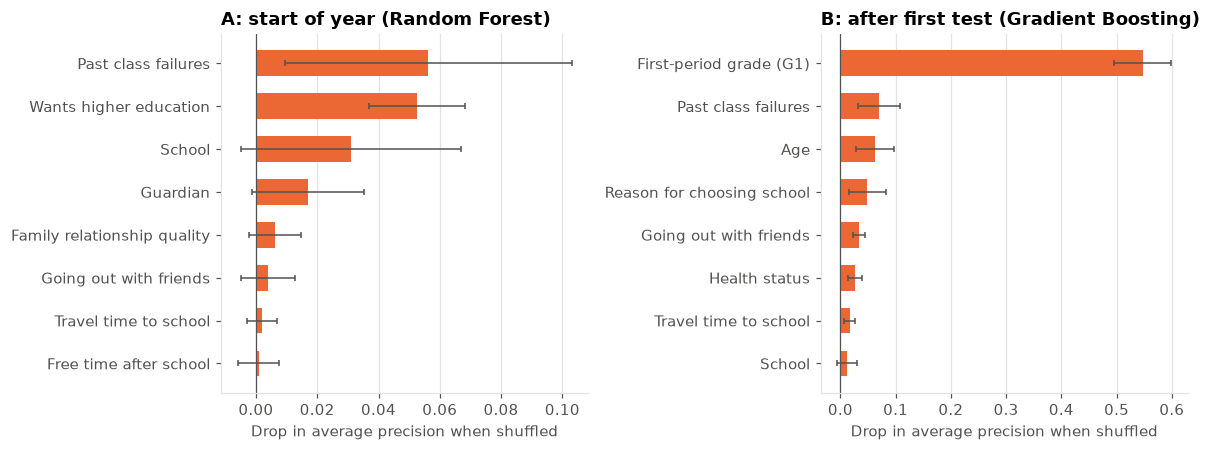

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
imp = {}
for ax, v in zip(axes, ["A", "B"]):
    b = models[v]
    t = permutation_importance_table(b["pipeline"], test[b["features"]], test["at_risk"]).head(8)[::-1]
    imp[v] = t
    ax.barh(t.label, t.importance, xerr=t["std"], color=RISK_C, height=0.6,
            error_kw=dict(ecolor=INK_2, lw=1, capsize=2))
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_title(f"{VERSION_LABELS[v]} ({b['model_name']})")
    ax.set_xlabel("Drop in average precision when shuffled")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_feature_importance.png", facecolor="white"); plt.show()

**Observations**
- **Version A** relies mainly on **past failures** and **wanting higher education**. These are the only two whose error bars stay clear of zero.
  **School** comes third, but its error bar is wide and crosses zero. With 130 test students this method can't reliably rank anything beyond the top two.
  (The SHAP view in section 4 and the coefficients in section 3, which use more data, both put school near the top.)
- **Version B** is dominated by **G1**: shuffling it drops average precision by about 0.55, roughly 8× more than the next feature.
  This matches Phase 3: once a grade exists, the grade is most of the story.

## 3 · Direction of effects: logistic regression coefficients (Version A, no sensitive features)

Tree models say *how much* a feature matters, but not *in which direction*. A logistic regression on the same
features shows the direction. Numeric features are standardised, so their coefficient is the effect of +1 standard deviation.
Categorical ones are the effect versus the reference category.
`C = 0.1` (moderate regularisation) is used so coefficients stay readable.

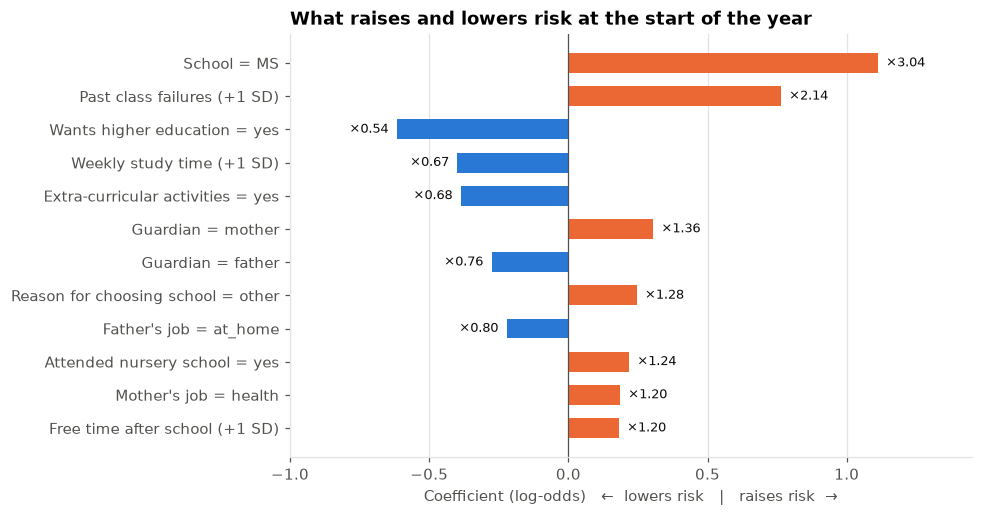

,term,coef,odds_ratio
0,school_MS,1.111,3.038
1,failures,0.763,2.144
2,higher_yes,-0.617,0.540
3,studytime,-0.399,0.671
4,activities_yes,-0.386,0.679
5,guardian_mother,0.304,1.356
6,guardian_father,-0.276,0.759
7,reason_other,0.245,1.278
8,Fjob_at_home,-0.222,0.801
9,nursery_yes,0.218,1.243


In [4]:
coefs = logistic_coefficients("A", train[all_features("A", SENSITIVE)], train["at_risk"], C=0.1, drop=SENSITIVE)
top = coefs.head(12)[::-1]

def term_label(term):
    for col in sorted(all_features("A"), key=len, reverse=True):
        if term == col:
            return label(col) + " (+1 SD)"
        if term.startswith(col + "_"):
            return f"{label(col)} = {term[len(col) + 1:]}"
    return term

fig, ax = plt.subplots(figsize=(8, 5))
colors = [RISK_C if c > 0 else PASS_C for c in top.coef]
ax.barh([term_label(t) for t in top.term], top.coef, color=colors, height=0.6)
ax.axvline(0, color=INK_2, lw=0.8)
for y, (c, o) in enumerate(zip(top.coef, top.odds_ratio)):
    ax.text(c + (0.03 if c > 0 else -0.03), y, f"×{o:.2f}", va="center",
            ha="left" if c > 0 else "right", fontsize=8.5, color=INK)
ax.set_xlabel("Coefficient (log-odds)   ←  lowers risk   |   raises risk  →")
ax.set_xlim(-1.0, 1.45)
ax.set_title("What raises and lowers risk at the start of the year")
fig.savefig(FIG_DIR / "09_logistic_coefficients.png", facecolor="white"); plt.show()
coefs.head(12).round(3)

**Observations** (×N = odds ratio: the factor by which the odds of failing change)
- **Raises risk:** attending **MS** (×3.0 odds), **each extra past failure** (+1 SD, ×2.1).
- **Lowers risk:** **wanting higher education** (×0.54), **more study time** (×0.67 per SD), **extra-curricular activities** (×0.68).
- These agree with the EDA and with the tree models, which makes the explanation more credible.
- These are **associations, not causes**. For example, making students join an activity won't necessarily cut failure;
  more engaged students may simply both join activities and pass.

## 4 · One student: why is this student flagged? (SHAP)

SHAP splits one prediction into contributions per feature: positive pushes risk **up**, negative pushes it **down**.
The example is a test-set student who was flagged by Version A, is at a school with a low base rate (GP), has **no past failures**,
and really did fail. This is the kind of student the simple rule misses.

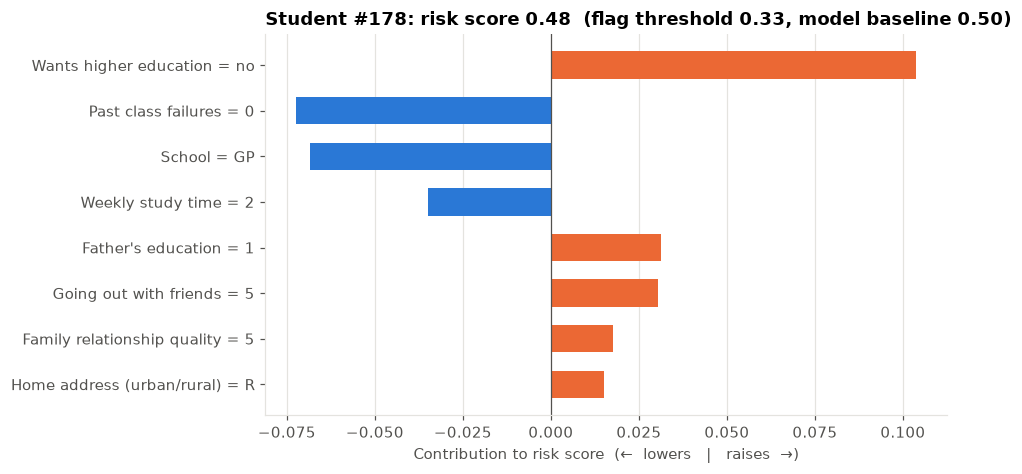

Top 3 reasons shown in the app:
  - Wants higher education: no  (+0.104)
  - Father's education: 1  (+0.031)
  - Going out with friends: 5  (+0.030)
Actual final grade G3 = 8


In [5]:
bA = models["A"]
pA = bA["pipeline"].predict_proba(test[bA["features"]])[:, 1]
pick = test.assign(p=pA)
pick = pick[(pick.at_risk == 1) & (pick.p >= bA["threshold"]) & (pick.failures == 0) & (pick.school == "GP")]
student = pick.sort_values("p", ascending=False).iloc[[0]]
contrib, base = shap_contributions(bA, student)
row = contrib.iloc[0]
top = row.reindex(row.abs().sort_values(ascending=False).index).head(8)[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([f"{label(f)} = {student.iloc[0][f]}" for f in top.index], top.values,
        color=[RISK_C if v > 0 else PASS_C for v in top.values], height=0.6)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Contribution to risk score  (←  lowers   |   raises  →)")
ax.set_title(f"Student #{student.index[0]}: risk score {student.p.iloc[0]:.2f}  "
             f"(flag threshold {bA['threshold']:.2f}, model baseline {base:.2f})")
fig.savefig(FIG_DIR / "10_student_explanation.png", facecolor="white"); plt.show()

print("Top 3 reasons shown in the app:")
for r in explain_student(bA, student, 3):
    print(f"  - {r['label']}: {r['value']}  (+{r['contribution']:.3f})")
print(f"Actual final grade G3 = {student.G3.iloc[0]}")

**Important: these are risk *scores*, not probabilities.** The models were trained with `class_weight="balanced"`,
which counts each at-risk student about 5× more so the model doesn't ignore the minority class. That moves all scores upward:
the model's baseline is about 0.50, although only 15% of students fail. The score is meaningful only **relative to the threshold** (0.33).
The app therefore shows a **risk band** based on the threshold, and does not say "48% chance of failing".

**Observations**
- The student has **no failure history**, so the rule "failures ≥ 1" would miss them.
  The model flags them through a **combination** of smaller signals (see the chart), each of which alone would not be alarming.
- This is the per-student view the app will show as **"Top 3 reasons"**.
- **A design issue for the app:** for students at MS, `School = MS` is often the top reason.
  That's true, but useless to a teacher who already works at MS, and it could read as "this student is at risk *because* of where they study".
  **Decision for Phase 5:** the app will show the top reasons **excluding `school`**, with a note that school-level risk is part of the score.

## 5 · Fairness audit: does the model work equally well for every group?

Computed on **5-fold out-of-fold predictions for all 649 students** (each student predicted by a model that never saw them),
because the 20 at-risk test students are too few to split by group. Bars show recall with a **bootstrap 95% interval**.
- **Recall** = share of at-risk students in the group who get flagged (missing them is the harm we care about most).
- **False-positive rate** = share of students in the group who are fine but get flagged anyway (unnecessary attention, possible stigma).

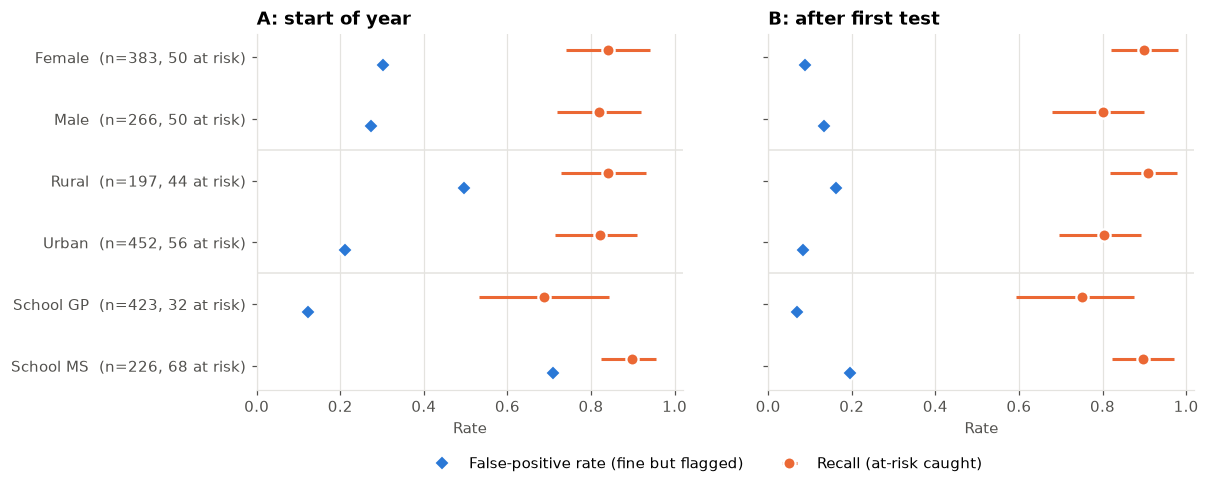

,version,attribute,group,n,n_at_risk,base_rate,flag_rate,recall,recall_lo,recall_hi,precision,fpr
6,A,sex,F,383,50,0.13,0.37,0.84,0.74,0.94,0.29,0.30
7,A,sex,M,266,50,0.19,0.38,0.82,0.72,0.92,0.41,0.27
8,A,address,R,197,44,0.22,0.57,0.84,0.73,0.93,0.33,0.50
9,A,address,U,452,56,0.12,0.29,0.82,0.71,0.91,0.35,0.21
10,A,school,GP,423,32,0.08,0.17,0.69,0.53,0.84,0.31,0.12
11,A,school,MS,226,68,0.30,0.77,0.90,0.82,0.96,0.35,0.71
24,B,sex,F,383,50,0.13,0.19,0.90,0.82,0.98,0.61,0.09
25,B,sex,M,266,50,0.19,0.26,0.80,0.68,0.90,0.58,0.13
26,B,address,R,197,44,0.22,0.33,0.91,0.82,0.98,0.62,0.16
27,B,address,U,452,56,0.12,0.17,0.80,0.70,0.89,0.58,0.08


In [6]:
g = groups[groups.variant == "No sensitive features"].copy()
nice = {"F": "Female", "M": "Male", "R": "Rural", "U": "Urban", "GP": "School GP", "MS": "School MS"}
g["name"] = g.group.map(nice) + "  (n=" + g.n.astype(str) + ", " + g.n_at_risk.astype(str) + " at risk)"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, v in zip(axes, ["A", "B"]):
    d = g[g.version == v].iloc[::-1].reset_index(drop=True)
    y = np.arange(len(d))
    ax.errorbar(d.recall, y + 0.12, xerr=[d.recall - d.recall_lo, d.recall_hi - d.recall], fmt="o",
                color=RISK_C, ms=8, mec="white", mew=1.5, ecolor=RISK_C, elinewidth=2, capsize=0,
                label="Recall (at-risk caught)")
    ax.plot(d.fpr, y - 0.12, "D", color=PASS_C, ms=7, mec="white", mew=1.5,
            label="False-positive rate (fine but flagged)")
    for i in [1.5, 3.5]:
        ax.axhline(i, color=GRID, lw=1)
    ax.set_yticks(y, d.name)
    ax.set_xlim(0, 1.02)
    ax.set_title(VERSION_LABELS[v])
    ax.set_xlabel("Rate")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.05, -0.15), ncol=2)
fig.savefig(FIG_DIR / "11_fairness.png", facecolor="white"); plt.show()

g[["version", "attribute", "group", "n", "n_at_risk", "base_rate", "flag_rate", "recall",
   "recall_lo", "recall_hi", "precision", "fpr"]].round(2)

**Observations**
- **Sex and urban/rural:** recall gaps are small (≤ 0.10), and every pair of 95% intervals overlaps heavily.
  No evidence of a gap, although with 50 at-risk students per group the test can only detect large ones.
- **School is the real fairness issue, in Version A especially:**
  - At **GP** the model catches only **69%** of at-risk students (95% CI 53–84%), versus **90%** at MS.
  - At **MS** it flags **77%** of *all* students, with a false-positive rate of **0.71**: most MS students who are fine get flagged too.
  - Cause: one global threshold applied to two schools with very different base rates (8% vs 30%). The model has learned "MS → higher risk", so MS students land above the threshold and GP students below it.
- **Version B** narrows the gap (GP 75%, MS 90%; FPR 0.07 vs 0.20) because G1 gives real individual evidence.

**What this means in practice:** a teacher uses the tool *inside one school*.
For a GP teacher the start-of-year list misses about 1 in 3 at-risk students. For an MS teacher it's a list of most of the class.
The fix is **school-specific thresholds** (calibrated on each school's own data), noted as future work in the README.
Simply dropping `school` would close the gap but lower precision for everyone (section 1).

## Summary

| Question | Answer |
|---|---|
| Does the model need sex, alcohol or relationship data? | **No.** Removing them changes ROC-AUC by < 0.005, so the app's models exclude them |
| What drives Version A? | Past failures, wanting higher education, school, study time |
| What drives Version B? | Overwhelmingly the first-period grade G1 |
| Gaps by sex or urban/rural? | Small, with overlapping 95% intervals |
| Gap by school? | **Yes.** Version A recall 69% at GP vs 90% at MS, and MS gets most students flagged. Fix: per-school thresholds (future work) |
| App design changes | "Top reasons" exclude `school`; show a **risk band**, not a probability (scores aren't calibrated); the About page states the school gap |